# Train on English, evaluate on Kazakh

The 300 translated conversations exist in both languages with identical structure and
identical entities. So the gap between a model's score on the English 300 and the
Kazakh 300 is the cost of the language change and **nothing else** — same
conversations, same labels, one variable. That is the experiment this dataset was
built to make possible.

It also tests the claim notebook 02 makes about feature groups: that `struct_` and
`entity_` survive translation while `surface_` and `lex_` do not. If that is right,
a model restricted to the invariant groups should lose almost nothing across the
language boundary, and a character n-gram model should fall off a cliff.

The experiment itself is `scripts/run_crosslingual.py`, imported here rather than
reimplemented.

Prerequisites:

```
python scripts/build_features.py  --merged data/merged --out data/features
python scripts/make_group_split.py --merged data/merged --out data/splits
```

In [1]:
import pathlib
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "scripts").is_dir())
sys.path.insert(0, str(ROOT / "scripts"))

import build_features as bf
import run_crosslingual as rx

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#dcdcd8"


def bare_axes(ax, xlabel=None):
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    return ax


features, merged = rx.load(ROOT / "data" / "features", ROOT / "data" / "merged")
print(f"{len(features):,} rows")

37,721 rows


## 1. Two contaminations had to be removed first

Neither was obvious, and the first version of this experiment reported numbers that
were badly wrong because of them.

**The split rule puts English twins in training.** Each Kazakh row inherits its
source's split — correct for the merged dataset, wrong here. 233 of the 300 English
twins sit in the training split, so a model trained on all English rows would have
read the English version of most conversations it is then tested on in Kazakh. That
is not zero-shot; it is memorisation with a translation step.

**Restylings are worse.** Holding out the 300 source rows is not enough. The
augmented pool rewrites one conversation in up to 25 voices, and 3,473 training rows
are restylings of 273 of the 300 — a median of 12 each. With those left in, a
character n-gram model scored **0.973** on the "held-out" English by recognising text
it had already read in another register.

So the whole conversation family goes out together.

In [2]:
train, english_300, kazakh = rx.split_sets(features, merged)

conversation = features.id.str.split("::").str[1]
source_ids = set(kazakh.translated_from)
held = set(conversation[features.id.isin(source_ids)])
naive = features[(features.language == "en") & (features.split == "train")
                 & (~features.id.isin(source_ids))]

print(f"English rows in the training split          {((features.language=='en') & (features.split=='train')).sum():,}")
print(f"  minus the 300 source rows                 {len(naive):,}")
print(f"  minus every restyling of them             {len(train):,}   <- what we train on")
print(f"\nrestylings removed: {len(naive) - len(train):,}, covering "
      f"{conversation[naive.index].isin(held).groupby(conversation[naive.index]).any().sum()} of the 300 conversations")
print(f"\nevaluation: {len(english_300)} EN and {len(kazakh)} KK -- the same conversations")

English rows in the training split          16,141
  minus the 300 source rows                 15,908
  minus every restyling of them             12,435   <- what we train on

restylings removed: 3,473, covering 273 of the 300 conversations

evaluation: 300 EN and 300 KK -- the same conversations


## 2. Results

Macro-F1. `EN-300` is unseen conversations in a seen language; `KK-300` is the same
unseen conversations in a language the model has never seen at all.

In [3]:
results = pd.read_csv(ROOT / "data" / "experiments" / "crosslingual_results.csv").set_index("model")
results.round(3)

,EN-300,KK-300,gap
model,,,
majority class,0.167,0.167,0.000
hand features (all 54),0.563,0.539,0.024
"hand features (struct+entity, 25)",0.343,0.346,-0.002
char n-gram TF-IDF (3-5),0.736,0.491,0.245
word TF-IDF (1-2),0.690,0.416,0.274


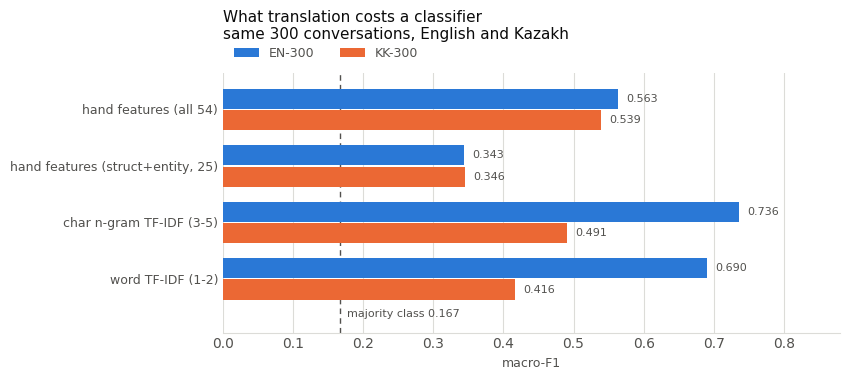

In [4]:
order = results.drop(index="majority class").index[::-1]
y = np.arange(len(order))
height = 0.36

fig, ax = plt.subplots(figsize=(8.6, 3.9))
ax.barh(y + height / 2 + 0.01, results.loc[order, "EN-300"], height=height,
        color=BLUE, label="EN-300")
ax.barh(y - height / 2 - 0.01, results.loc[order, "KK-300"], height=height,
        color=ORANGE, label="KK-300")

for i, name in enumerate(order):
    ax.text(results.loc[name, "EN-300"] + 0.012, i + height / 2 + 0.01,
            f"{results.loc[name, 'EN-300']:.3f}", va="center", fontsize=8, color=MUTED)
    ax.text(results.loc[name, "KK-300"] + 0.012, i - height / 2 - 0.01,
            f"{results.loc[name, 'KK-300']:.3f}", va="center", fontsize=8, color=MUTED)

baseline = results.loc["majority class", "EN-300"]
ax.axvline(baseline, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=0)
ax.text(baseline + 0.01, -0.62, f"majority class {baseline:.3f}",
        fontsize=8, color=MUTED, va="center")

ax.set_yticks(y)
ax.set_yticklabels(order, fontsize=9)
ax.set_title("What translation costs a classifier\nsame 300 conversations, English and Kazakh",
             loc="left", color=INK, fontsize=11, pad=24)
bare_axes(ax, "macro-F1")
ax.set_xlim(0, 0.88)
ax.set_ylim(-0.95, len(order) - 0.35)
ax.legend(frameon=False, ncol=2, labelcolor=MUTED, fontsize=9,
          loc="lower left", bbox_to_anchor=(0, 1.005))
plt.tight_layout()
plt.show()

## 3. What it says

**The feature grouping from notebook 02 holds up.** That was a prediction made before
any model was trained, and it survived:

| Model | gap | reading |
|---|---:|---|
| hand features, `struct_`+`entity_` only | **−0.002** | transfers perfectly, as designed |
| hand features, all 54 | +0.024 | nearly free |
| char n-gram TF-IDF | +0.245 | falls off the script boundary |
| word TF-IDF | +0.274 | worst — Kazakh words are not English words |

**There is a real trade between accuracy and transferability.** Char n-grams are the
strongest model in English (0.736) and among the weakest in Kazakh (0.491). The hand
features are *worse* in English (0.563) and *better* in Kazakh (0.539). On the
language the project is actually about, the interpretable language-aware features
win.

**The invariant-only model transfers perfectly and is nearly useless.** 0.343 against
a 0.167 majority baseline. Structure and entity counts carry real but thin signal;
they are not a classifier on their own. Perfect transfer of a weak signal is not a
solution.

**Everything is low.** The best Kazakh score is 0.539 against a 0.167 baseline — far
better than chance, nowhere near usable. These are deliberately simple models on
hand-built features; the honest conclusion is that the task is not solved, not that
it is unsolvable.

In [5]:
print((ROOT / "data" / "experiments" / "crosslingual_report.md").read_text().split("## Per-class")[1])

, hand features on Kazakh

```
              precision    recall  f1-score   support

  LEGITIMATE       0.67      0.78      0.72       100
        SCAM       0.44      0.24      0.31       100
  SUSPICIOUS       0.52      0.67      0.58       100

    accuracy                           0.56       300
   macro avg       0.54      0.56      0.54       300
weighted avg       0.54      0.56      0.54       300

```



## 4. How much of this can we trust?

300 conversations per evaluation set, 100 per class.

In [6]:
for n, score in [(300, 0.54), (100, 0.54)]:
    half = 1.96 * np.sqrt(score * (1 - score) / n)
    print(f"n={n:<4} score {score:.2f}  ->  95% CI +/- {100*half:.1f} points")
print()
print("So: the gaps of 0.245 and 0.274 are real. The difference between")
print("0.539 and 0.491 is not -- those two models are tied as far as this")
print("evaluation set can tell. Any follow-up that wants to separate models")
print("a few points apart needs more Kazakh data.")

n=300  score 0.54  ->  95% CI +/- 5.6 points
n=100  score 0.54  ->  95% CI +/- 9.8 points

So: the gaps of 0.245 and 0.274 are real. The difference between
0.539 and 0.491 is not -- those two models are tied as far as this
evaluation set can tell. Any follow-up that wants to separate models
a few points apart needs more Kazakh data.


## 5. What this changes

**For the project.** The claim "we built a Kazakh evaluation slice and it is useful"
is now demonstrated rather than asserted: it detected a 0.245 transfer gap that no
amount of English evaluation would have revealed.

**For the corpus.** Finding the restyling leak means every score previously measured
against ScamBench's own splits is inflated — including ours. Notebook 02's signal
check now reports both splits side by side: 0.783 on the original, **0.709** on the
grouped one.

**What to do next**, in order of value:

1. **A multilingual encoder.** Char n-grams cannot cross a script boundary by
   construction. An mBERT/XLM-R/LaBSE representation is the obvious thing to try, and
   this notebook is now the baseline it has to beat.
2. **More Kazakh** — the corpus can supply up to 747 conversations per class without
   any external dataset, against the 100 per class translated so far. Worth doing
   *after* step 1, because its value is narrowing confidence intervals on a
   comparison, and right now there is no comparison worth narrowing.
3. **Translate-train.** Machine-translate a slice of English training data into
   Kazakh and train on the mixture, using the 300 human translations as the gold test
   set. Standard practice, and the clean split makes it safe to measure.